I**T2011 - AI & ML Group Assignment**


Healthcare Diabetes Dataset :End-to-End ML Pipeline

Dataset: Healthcare Diabetes Dataset (Kaggle)


Group Members:

IT25101078 - Nirasha W.A.C

IT25101090 - Jayathilaka W.M.U.S

IT25101091 - Umer D.R.S

IT25101105 - Arachchi B.A.K.S.V

IT25101124 - Weerasekara G.W.D.S

IT25101133 - Kodagoda S.K


In [1]:
# ---- Setup ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# XGBoost classifier
from xgboost import XGBClassifier

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


Step 1:Load the dataset

In [4]:
# ---- Load the Healthcare Diabetes dataset ----
# Try to load via Google Drive, otherwise fall back to local upload

import os
import pandas as pd

DATA_PATH = '/content/Healthcare-Diabetes.csv'

try:
    from google.colab import drive
    print("Attempting to mount Google Drive...")
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/dataset/Healthcare-Diabetes.csv'
    print("Successfully mounted Google Drive!")
except Exception as e:
    print(f"Google Drive mount skipped or failed: {e}")
    print("Using direct/local upload path instead.")
    DATA_PATH = '/content/Healthcare-Diabetes.csv'

# Read the dataset
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print(f"Error: CSV file not found at {DATA_PATH}. Please upload the 'Healthcare-Diabetes.csv' file to Colab.")


Attempting to mount Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully mounted Google Drive!
Dataset shape: (2768, 10)


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.info()
print("\nShape:", df.shape)
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB

Shape: (2768, 10)


,count,mean,std,min,25%,50%,75%,max
Id,2768.0,1384.500000,799.197097,1.000,692.750,1384.500,2076.250,2768.00
Pregnancies,2768.0,3.742775,3.323801,0.000,1.000,3.000,6.000,17.00
Glucose,2768.0,121.102601,32.036508,0.000,99.000,117.000,141.000,199.00
BloodPressure,2768.0,69.134393,19.231438,0.000,62.000,72.000,80.000,122.00
SkinThickness,2768.0,20.824422,16.059596,0.000,0.000,23.000,32.000,110.00
Insulin,2768.0,80.127890,112.301933,0.000,0.000,37.000,130.000,846.00
BMI,2768.0,32.137392,8.076127,0.000,27.300,32.200,36.625,80.60
DiabetesPedigreeFunction,2768.0,0.471193,0.325669,0.078,0.244,0.375,0.624,2.42
Age,2768.0,33.132225,11.777230,21.000,24.000,29.000,40.000,81.00
Outcome,2768.0,0.343931,0.475104,0.000,0.000,0.000,1.000,1.00


Step 2: Data Preprocessing and Analysis

### 2.0 Checking for and removing duplicate patient records

Before any cleaning, we checked whether every row represents a genuinely distinct patient. This matters
because if the same patient's record appears more than once and we later split the data into train/test sets,
copies of the same patient can end up on both sides of the split — the model would then be partly "tested" on
data it already memorised during training (data leakage), making every downstream metric look better than it
really is.


In [6]:
# Check for fully duplicated patient records (same values across every clinical feature + Outcome)
feature_cols_check = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                       'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

n_before = len(df)
n_duplicates = df.duplicated(subset=feature_cols_check).sum()
print(f"Rows before deduplication: {n_before}")
print(f"Fully duplicated patient records found: {n_duplicates}")

df = df.drop_duplicates(subset=feature_cols_check).reset_index(drop=True)
n_after = len(df)
print(f"Rows after deduplication: {n_after}  ({n_after/n_before:.1%} of original rows kept)")
print(f"\nThe dataset supplied ({n_before} rows) turned out to contain only {n_after} unique patients "
      f"— i.e. it is the well-known {n_after}-row Pima Indians Diabetes dataset repeated ~{n_before/n_after:.1f}x. "
      f"All further preprocessing and modelling below uses only the {n_after} unique records.")


Rows before deduplication: 2768
Fully duplicated patient records found: 1990
Rows after deduplication: 778  (28.1% of original rows kept)

The dataset supplied (2768 rows) turned out to contain only 778 unique patients — i.e. it is the well-known 778-row Pima Indians Diabetes dataset repeated ~3.6x. All further preprocessing and modelling below uses only the 778 unique records.


2.1 Handling missing data

In [7]:
# List of columns where a zero value is actually invalid
cols_with_invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Count of zero values per column (before treatment):")
# Count how many zeros exist in each of these column
print((df[cols_with_invalid_zero] == 0).sum())

df_clean = df.copy()
df_clean[cols_with_invalid_zero] = df_clean[cols_with_invalid_zero].replace(0, np.nan)

print("\nMissing values after converting zeros to NaN:")
print(df_clean.isnull().sum())

imputer = SimpleImputer(strategy='median')
df_clean[cols_with_invalid_zero] = imputer.fit_transform(df_clean[cols_with_invalid_zero])

print("\nMissing values after median imputation:")
print(df_clean.isnull().sum())


Count of zero values per column (before treatment):
Glucose            5
BloodPressure     36
SkinThickness    229
Insulin          377
BMI               11
dtype: int64

Missing values after converting zeros to NaN:
Id                            0
Pregnancies                   0
Glucose                       5
BloodPressure                36
SkinThickness               229
Insulin                     377
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after median imputation:
Id                          0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


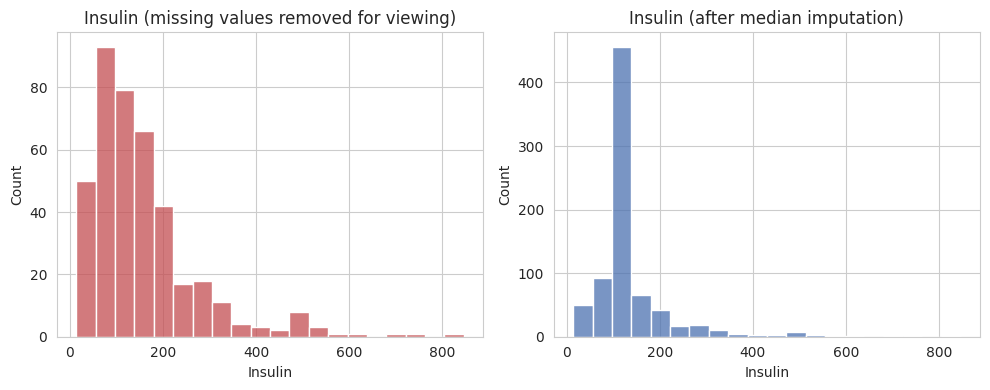

In [8]:
# EDA visualization for Member 1: distribution before vs after imputation (example: Insulin)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df['Insulin'].replace(0, np.nan).dropna(), ax=axes[0], color='#C44E52', bins=20)
axes[0].set_title('Insulin (missing values removed for viewing)')
sns.histplot(df_clean['Insulin'], ax=axes[1], color='#4C72B0', bins=20)
axes[1].set_title('Insulin (after median imputation)')
plt.tight_layout()
plt.show()


2.2 Encoding categorical variables

In [9]:
df_enc = df_clean.copy()

# Derive a categorical variable to encode
df_enc['BMI_Category'] = pd.cut(df_enc['BMI'], bins=[0, 18.5, 25, 30, 100],
                                 labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

print(df_enc['BMI_Category'].value_counts())

# One-hot encode
df_enc = pd.get_dummies(df_enc, columns=['BMI_Category'], drop_first=True)
df_enc.head()


BMI_Category
Obese          485
Overweight     180
Normal         109
Underweight      4
Name: count, dtype: int64


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_Category_Normal,BMI_Category_Overweight,BMI_Category_Obese
0,1,6,148.0,72.0,35.0,126.0,33.6,0.627,50,1,False,False,True
1,2,1,85.0,66.0,29.0,126.0,26.6,0.351,31,0,False,True,False
2,3,8,183.0,64.0,29.0,126.0,23.3,0.672,32,1,True,False,False
3,4,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,False,True,False
4,5,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,False,False,True


/tmp/ipykernel_2874/512145461.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.cut(df_clean['BMI'], bins=[0,18.5,25,30,100],


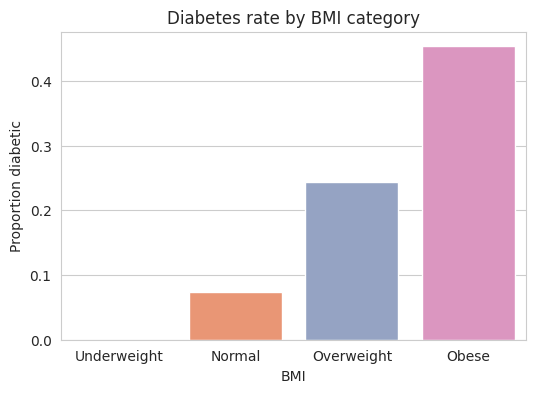

In [10]:
# EDA visualization for Member 2: outcome rate by BMI category
plt.figure(figsize=(6,4))
sns.barplot(x=pd.cut(df_clean['BMI'], bins=[0,18.5,25,30,100],
                      labels=['Underweight','Normal','Overweight','Obese']),
            y=df_clean['Outcome'], palette='Set2', errorbar=None)
plt.ylabel('Proportion diabetic')
plt.title('Diabetes rate by BMI category')
plt.show()


### 2.3 Outlier removal


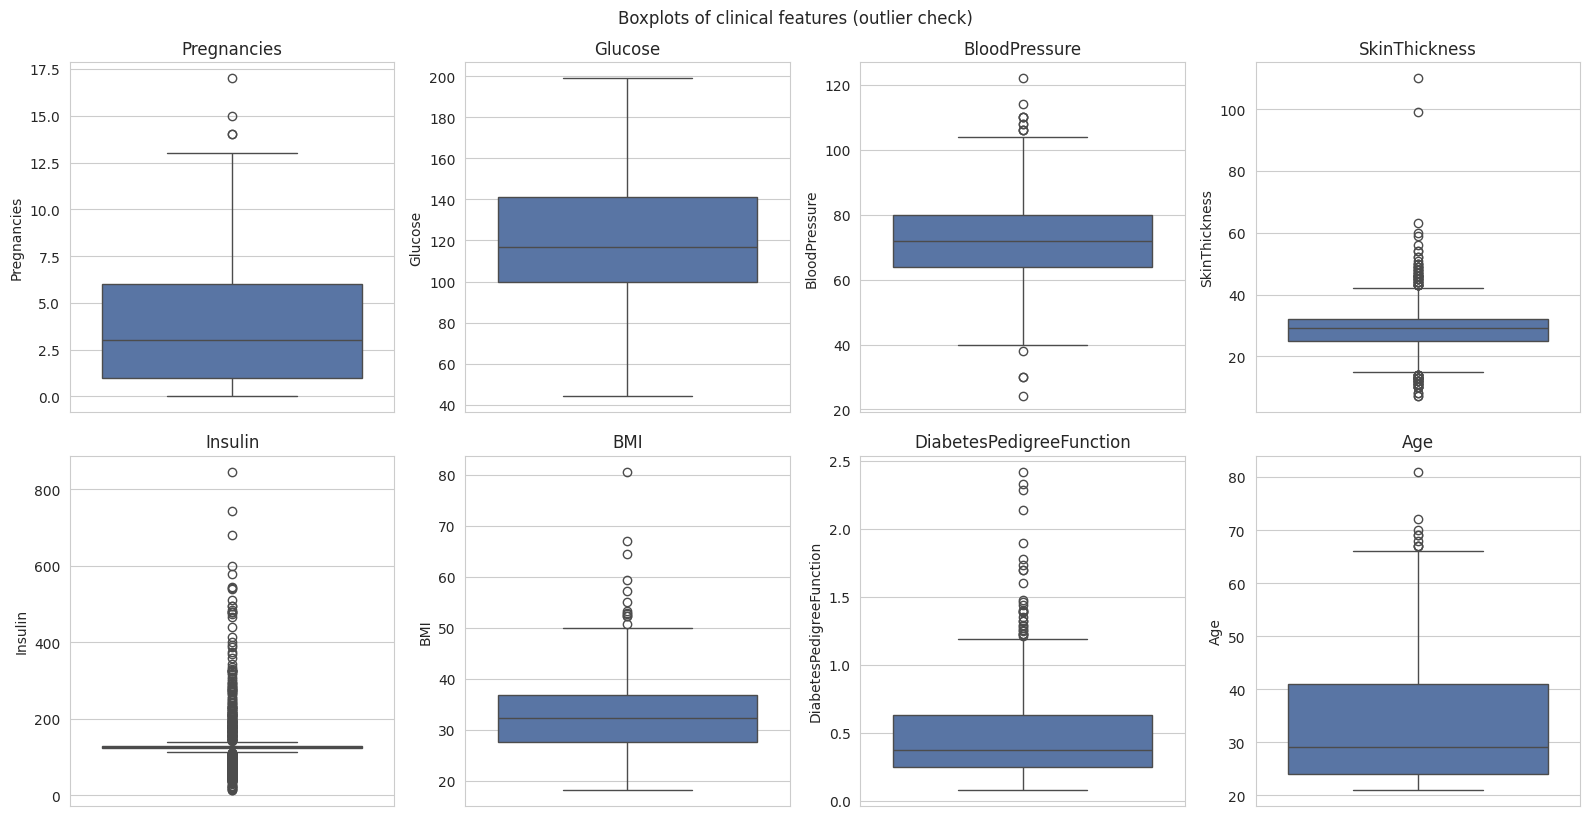

In [11]:
#boxplot for each clinical feature
feature_cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(y=df_enc[col], ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout()
plt.suptitle("Boxplots of clinical features (outlier check)", y=1.02)
plt.show()

In [12]:
def remove_outliers_iqr(data, cols, k=1.5):
    data = data.copy()
    mask = pd.Series(True, index=data.index)
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k*iqr, q3 + k*iqr
        mask &= data[col].between(lower, upper)
    return data[mask]

print("Rows before outlier removal:", len(df_enc))
df_no_outliers = remove_outliers_iqr(df_enc, feature_cols)
print("Rows after outlier removal:", len(df_no_outliers))


Rows before outlier removal: 778
Rows after outlier removal: 385


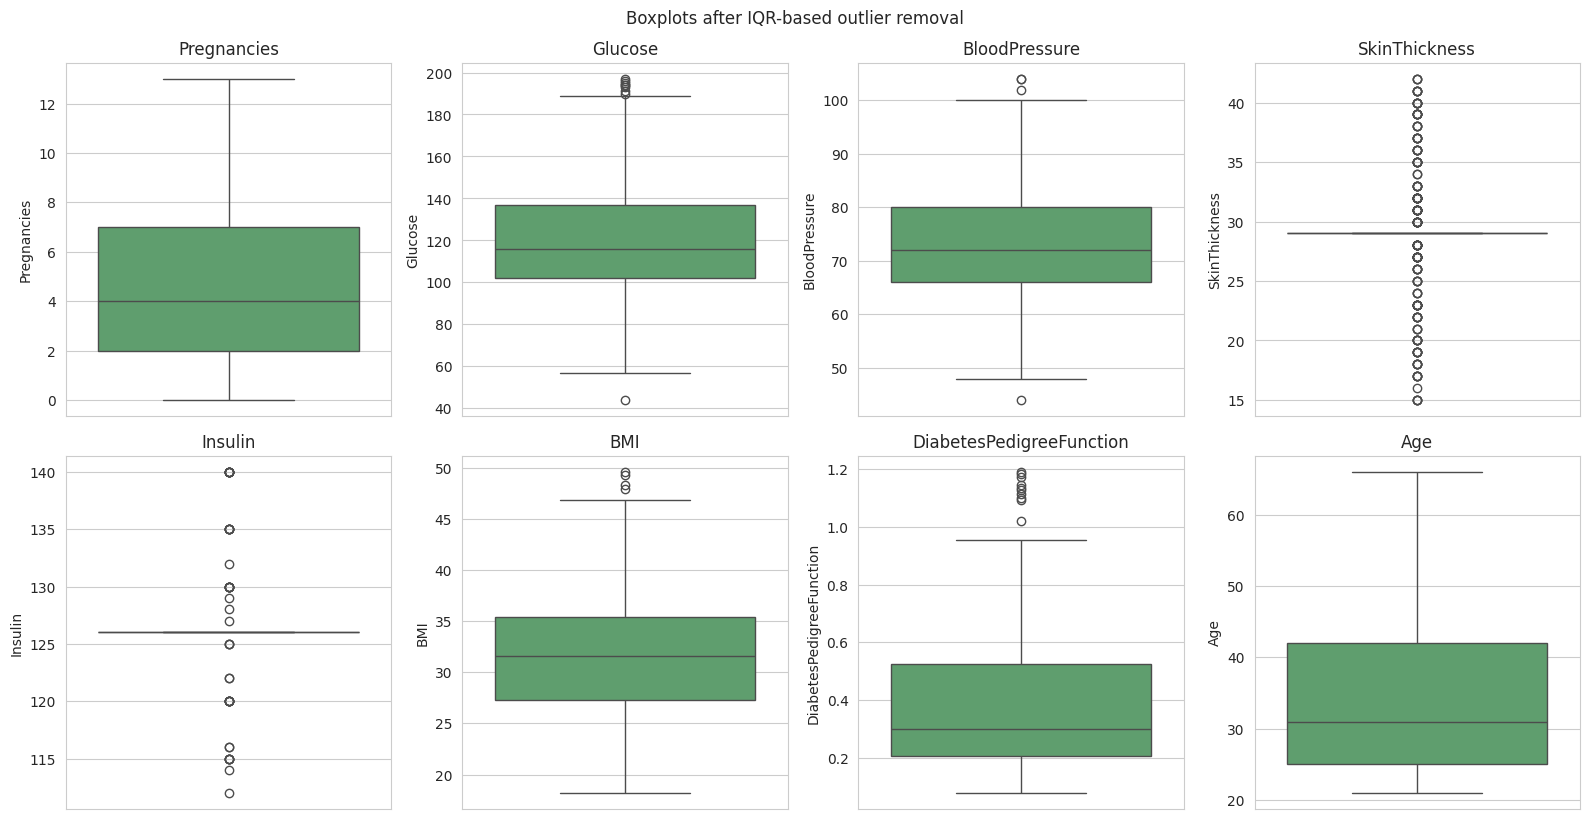

In [13]:
# EDA visualization for Member 3: boxplot after outlier removal
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(y=df_no_outliers[col], ax=ax, color='#55A868')
    ax.set_title(col)
plt.tight_layout()
plt.suptitle("Boxplots after IQR-based outlier removal", y=1.02)
plt.show()

**Decision: outliers are investigated but not dropped from the modelling dataset.**

The IQR check above removes rows that fall outside 1.5×IQR on *any* of the 8 clinical features. Applied
across 8 features simultaneously, this is a very strict filter — cumulative across columns, it discards
roughly half the dataset (see figures printed below), and it removes diabetic and non-diabetic patients in
similar proportion. Critically, many of the flagged "outliers" are patients with high Glucose, high Insulin
or high BMI — precisely the values that clinically *define* diabetes risk. Deleting them would not be
removing data-entry errors, it would be removing the very patients the model most needs to learn from, and
would shrink an already small dataset even further.

**Conclusion:** the outlier analysis is kept as an EDA/data-quality investigation (useful insight for Step 2 —
"provide insights and patterns observed in the data"), but `df_no_outliers` is *not* used to build the
final preprocessed file. `df_clean` (deduplicated + missing-value-imputed) is what gets saved and passed to
the six models in Step 3, each of which applies its own additional handling (e.g. scaling) as appropriate.


In [14]:
# Quantify the cost of applying IQR outlier removal, to justify the decision above
print(f"Rows before outlier removal: {len(df_enc)}")
print(f"Rows after outlier removal: {len(df_no_outliers)}  ({len(df_no_outliers)/len(df_enc):.1%} kept)")
print()
removed_pos = (df_enc['Outcome'] == 1).sum() - (df_no_outliers['Outcome'] == 1).sum()
removed_neg = (df_enc['Outcome'] == 0).sum() - (df_no_outliers['Outcome'] == 0).sum()
print(f"Diabetic patients removed as 'outliers': {removed_pos} of {(df_enc['Outcome'] == 1).sum()}")
print(f"Non-diabetic patients removed as 'outliers': {removed_neg} of {(df_enc['Outcome'] == 0).sum()}")
print("\n-> Outliers are documented here, but NOT dropped from df_clean / the saved file.")


Rows before outlier removal: 778
Rows after outlier removal: 385  (49.5% kept)

Diabetic patients removed as 'outliers': 132 of 272
Non-diabetic patients removed as 'outliers': 261 of 506

-> Outliers are documented here, but NOT dropped from df_clean / the saved file.


2.4 Normalization / scaling

In [15]:
scaler = StandardScaler()
df_scaled = df_no_outliers.copy()
df_scaled[feature_cols] = scaler.fit_transform(df_scaled[feature_cols])
df_scaled[feature_cols].describe().T[['mean','std','min','max']]


,mean,std,min,max
Pregnancies,-1.107339e-16,1.001301,-1.300889,2.604900
Glucose,-5.536697e-17,1.001301,-2.675854,2.680674
BloodPressure,3.437366e-16,1.001301,-2.805287,2.993043
SkinThickness,1.614870e-16,1.001301,-2.950938,2.738046
Insulin,1.024289e-15,1.001301,-4.596415,4.508575
BMI,3.944896e-16,1.001301,-2.171264,2.869431
DiabetesPedigreeFunction,9.227828e-18,1.001301,-1.278272,3.317065
Age,-6.920871e-17,1.001301,-1.170635,2.732608


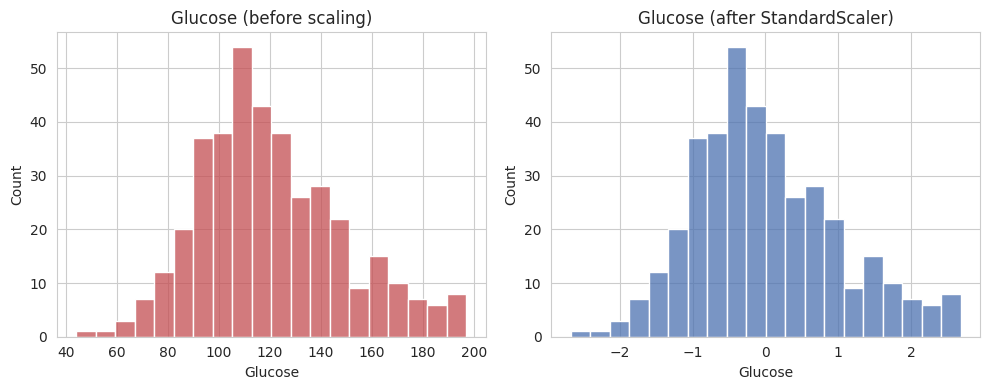

In [16]:
# EDA visualization for Member 4: before vs after scaling (example: Glucose)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df_no_outliers['Glucose'], ax=axes[0], color='#C44E52', bins=20)
axes[0].set_title('Glucose (before scaling)')
sns.histplot(df_scaled['Glucose'], ax=axes[1], color='#4C72B0', bins=20)
axes[1].set_title('Glucose (after StandardScaler)')
plt.tight_layout()
plt.show()


2.5  Feature engineering - feature selection

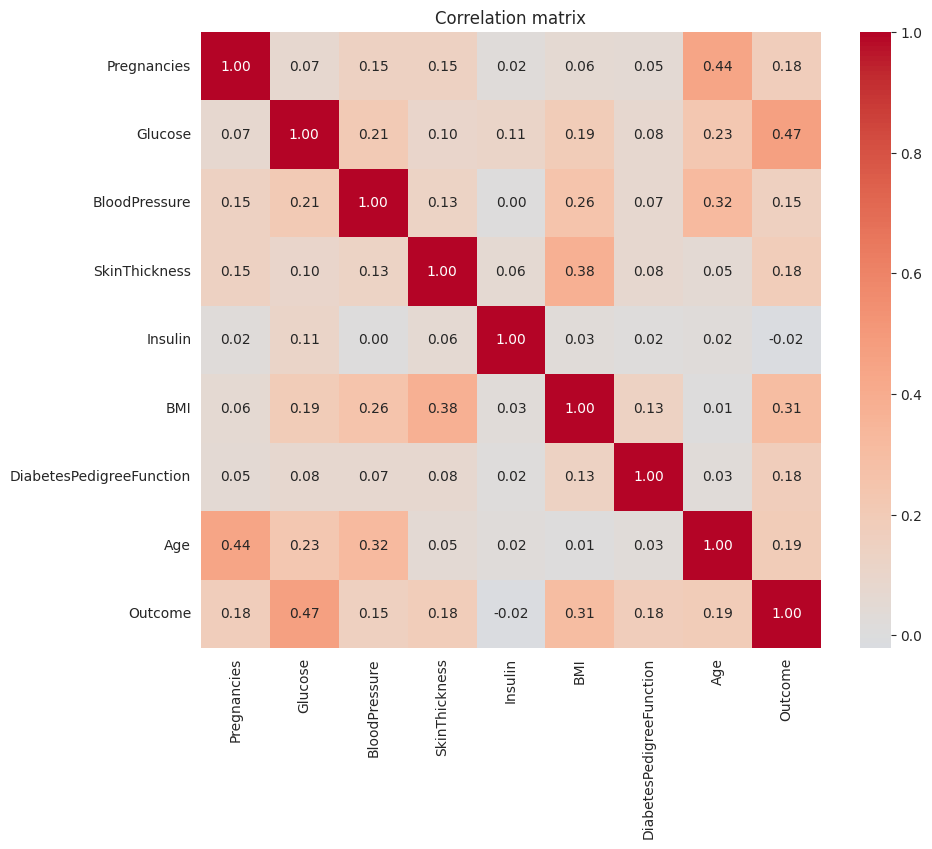

Correlation with target (Outcome):
Glucose                     0.469119
BMI                         0.305228
Age                         0.192745
SkinThickness               0.183478
Pregnancies                 0.179775
DiabetesPedigreeFunction    0.175649
BloodPressure               0.150800
Insulin                    -0.020910
Name: Outcome, dtype: float64


In [17]:
plt.figure(figsize=(10,8))
corr = df_scaled[feature_cols + ['Outcome']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0) #construct a correlation matrix
plt.title('Correlation matrix')
plt.show()

corr_with_target = corr['Outcome'].drop('Outcome').sort_values(ascending=False)
print("Correlation with target (Outcome):")
print(corr_with_target)


In [18]:
# Select features above a chosen absolute-correlation threshold
threshold = 0.10
selected_features = corr_with_target[abs(corr_with_target) >= threshold].index.tolist()
print(f"Selected features (|corr| >= {threshold}):", selected_features)


Selected features (|corr| >= 0.1): ['Glucose', 'BMI', 'Age', 'SkinThickness', 'Pregnancies', 'DiabetesPedigreeFunction', 'BloodPressure']


2.6 Feature engineering — dimension reduction (PCA)

In [19]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)  # keep 95% variance
X_pca = pca.fit_transform(df_scaled[feature_cols])

print("Original number of features:", len(feature_cols))
print("Number of PCA components retained:", pca.n_components_)
print("Explained variance ratio per component:", np.round(pca.explained_variance_ratio_, 3))
print("Cumulative explained variance:", np.round(np.cumsum(pca.explained_variance_ratio_), 3))


Original number of features: 8
Number of PCA components retained: 8
Explained variance ratio per component: [0.246 0.164 0.129 0.12  0.118 0.094 0.072 0.059]
Cumulative explained variance: [0.246 0.409 0.538 0.658 0.775 0.87  0.941 1.   ]


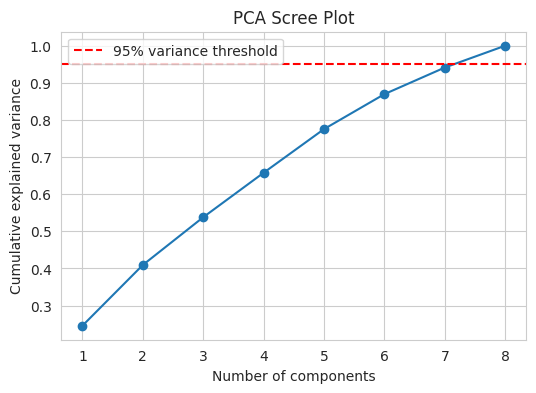

In [20]:
# EDA visualization for Member 6: cumulative explained variance (scree plot)
plt.figure(figsize=(6,4))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance threshold')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.show()


In [22]:
# Final sanity check before saving
print('Final preprocessed shape:', df_clean.shape)
print('Remaining duplicate rows:', df_clean.duplicated(subset=feature_cols_check).sum())
print('Remaining missing values:', df_clean.isnull().sum().sum())

# 1. Save the preprocessed DataFrame to a CSV file in Colab
df_clean.to_csv('preprocessed_data.csv', index=False)

# 2. Trigger an automatic download to your computer
from google.colab import files
files.download('preprocessed_data.csv')

Final preprocessed shape: (778, 10)
Remaining duplicate rows: 0
Remaining missing values: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Step 3: XGBoost Model Training & Evaluation

With preprocessing complete, we train **XGBoost (Extreme Gradient Boosting)** for binary diabetes classification.

**Why XGBoost?**
- It performs very well on structured/tabular clinical data.
- It can learn non-linear relationships and feature interactions.
- It is robust to different feature scales, so StandardScaler is not required for the tree-based model.
- Regularisation parameters help control overfitting.
- It provides feature-importance scores that are useful for interpretation.

As decided in Section 2.3, modelling uses `df_clean` (deduplicated + median-imputed) rather than the outlier-filtered EDA dataset. This keeps clinically meaningful high-risk patients in the training data.

**Target:** `Outcome`  
- `0` = Non-diabetic
- `1` = Diabetic


### 3.1 Train/test split

In [23]:
X = df_clean[feature_cols]
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nClass balance - Training set:")
print(y_train.value_counts(normalize=True).round(3))

print("\nClass balance - Test set:")
print(y_test.value_counts(normalize=True).round(3))


Training set: (622, 8)
Test set: (156, 8)

Class balance - Training set:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Class balance - Test set:
Outcome
0    0.647
1    0.353
Name: proportion, dtype: float64


### 3.2 Build and train the baseline XGBoost model

The first model uses sensible regularised starting parameters. `eval_metric='logloss'` is appropriate for binary classification, while subsampling and column sampling reduce overfitting.


In [24]:
xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("Baseline XGBoost model trained successfully.")


Baseline XGBoost model trained successfully.


### 3.3 Baseline model predictions and evaluation


In [25]:
# Class predictions and probability predictions
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

baseline_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}

baseline_metrics_df = pd.DataFrame(
    baseline_metrics.items(),
    columns=['Metric', 'Score']
)

display(baseline_metrics_df.style.format({'Score': '{:.4f}'}))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    zero_division=0
))


,Metric,Score
0,Accuracy,0.7756
1,Precision,0.6852
2,Recall,0.6727
3,F1 Score,0.6789
4,ROC-AUC,0.8353



Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.82      0.83      0.83       101
    Diabetic       0.69      0.67      0.68        55

    accuracy                           0.78       156
   macro avg       0.75      0.75      0.75       156
weighted avg       0.77      0.78      0.78       156



### 3.4 Confusion matrix

The confusion matrix shows:
- **True Negative (TN):** correctly predicted non-diabetic patients
- **False Positive (FP):** non-diabetic patients predicted as diabetic
- **False Negative (FN):** diabetic patients predicted as non-diabetic
- **True Positive (TP):** correctly predicted diabetic patients


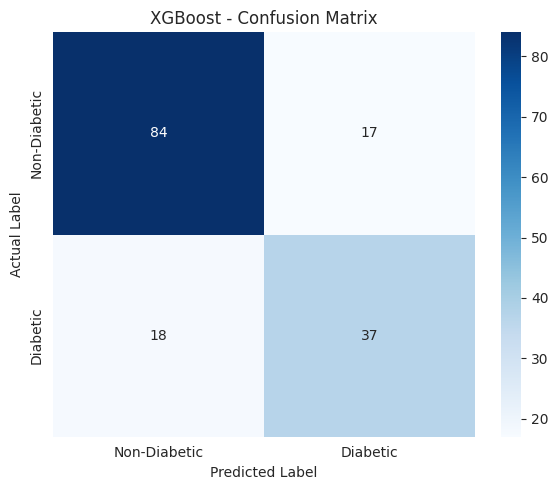

True Negatives : 84
False Positives: 17
False Negatives: 18
True Positives : 37


In [26]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('XGBoost - Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")


### 3.5 ROC curve and AUC

ROC-AUC evaluates how well the model separates diabetic and non-diabetic patients across all possible classification thresholds. A value closer to **1.0** indicates stronger discrimination.


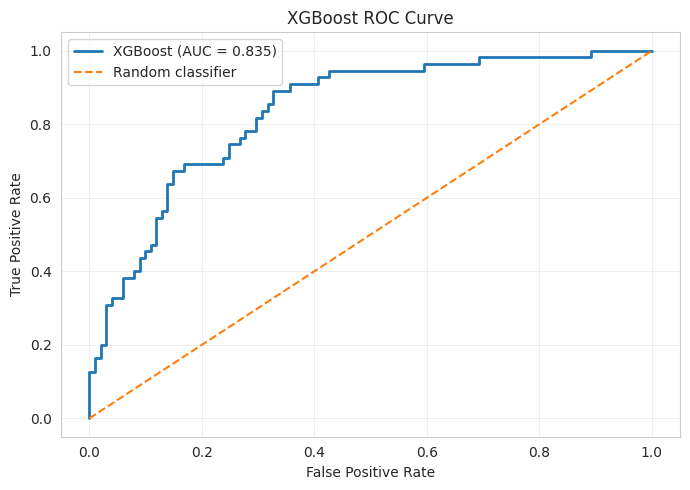

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, label=f'XGBoost (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.6 Feature importance

XGBoost assigns an importance score to each clinical feature. Larger values indicate that the feature contributed more to the fitted decision trees.


,Feature,Importance
1,Glucose,0.273143
5,BMI,0.136054
7,Age,0.129634
4,Insulin,0.101531
6,DiabetesPedigreeFunction,0.095969
0,Pregnancies,0.092837
3,SkinThickness,0.085664
2,BloodPressure,0.085168


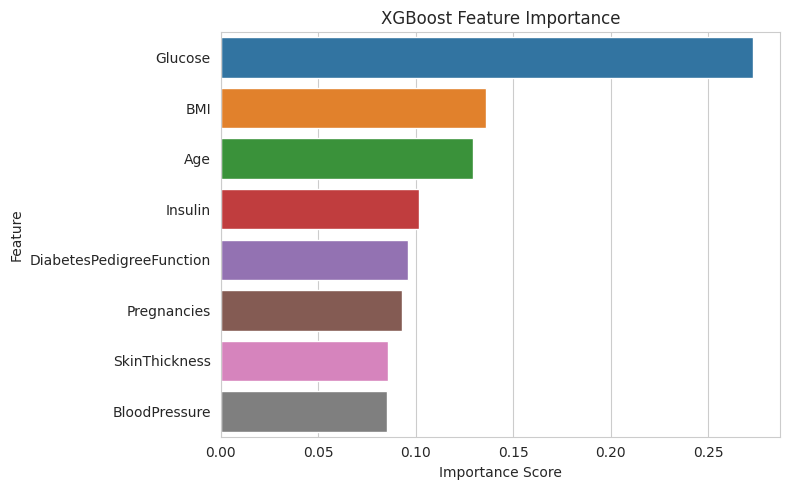

In [28]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False
)
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### 3.7 Stratified 5-fold cross-validation

A single train/test split can vary depending on which patients fall into the test set. Stratified 5-fold cross-validation gives a more stable estimate while preserving the class ratio in every fold.


In [29]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_accuracy = cross_val_score(
    xgb_model, X, y,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

cv_auc = cross_val_score(
    xgb_model, X, y,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("5-Fold Accuracy scores:", np.round(cv_accuracy, 4))
print(f"Mean CV Accuracy: {cv_accuracy.mean():.4f} ± {cv_accuracy.std():.4f}")

print("\n5-Fold ROC-AUC scores:", np.round(cv_auc, 4))
print(f"Mean CV ROC-AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")


5-Fold Accuracy scores: [0.7179 0.7628 0.7885 0.7484 0.7419]
Mean CV Accuracy: 0.7519 ± 0.0233

5-Fold ROC-AUC scores: [0.7901 0.827  0.8553 0.8172 0.8575]
Mean CV ROC-AUC: 0.8294 ± 0.0251


### 3.8 Hyperparameter tuning with GridSearchCV

We tune a small set of important XGBoost parameters using **Stratified 5-fold cross-validation**. The search is intentionally compact so that it is practical to run in Google Colab.

The optimisation metric is **ROC-AUC**, which is suitable for this imbalanced medical classification problem.


In [30]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.10],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_for_tuning = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=xgb_for_tuning,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print(f"Best cross-validation ROC-AUC: {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best cross-validation ROC-AUC: 0.8227


### 3.9 Evaluate the tuned XGBoost model on the unseen test set


In [31]:
best_xgb_model = grid_search.best_estimator_

y_pred_tuned = best_xgb_model.predict(X_test)
y_prob_tuned = best_xgb_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned, zero_division=0),
    'Recall': recall_score(y_test, y_pred_tuned, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred_tuned, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_tuned)
}

comparison_df = pd.DataFrame({
    'Metric': list(baseline_metrics.keys()),
    'Baseline XGBoost': list(baseline_metrics.values()),
    'Tuned XGBoost': [tuned_metrics[m] for m in baseline_metrics.keys()]
})

display(
    comparison_df.style.format({
        'Baseline XGBoost': '{:.4f}',
        'Tuned XGBoost': '{:.4f}'
    })
)

print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=['Non-Diabetic', 'Diabetic'],
    zero_division=0
))


,Metric,Baseline XGBoost,Tuned XGBoost
0,Accuracy,0.7756,0.7564
1,Precision,0.6852,0.6809
2,Recall,0.6727,0.5818
3,F1 Score,0.6789,0.6275
4,ROC-AUC,0.8353,0.8268



Tuned Model Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.79      0.85      0.82       101
    Diabetic       0.68      0.58      0.63        55

    accuracy                           0.76       156
   macro avg       0.73      0.72      0.72       156
weighted avg       0.75      0.76      0.75       156



### 3.10 Tuned model confusion matrix and ROC curve


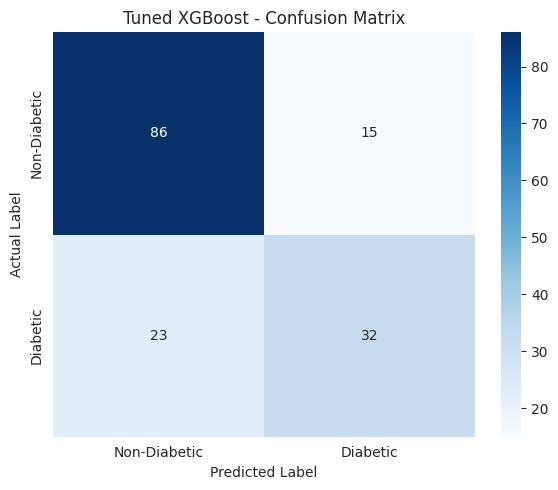

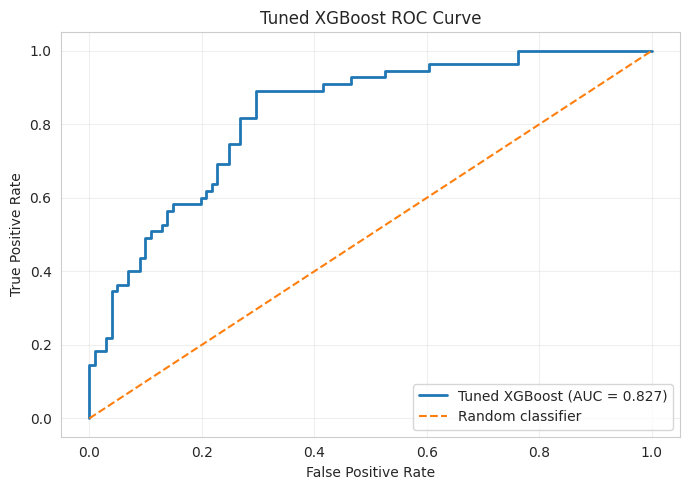

In [32]:
# Tuned confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Tuned XGBoost - Confusion Matrix')
plt.tight_layout()
plt.show()

# Tuned ROC curve
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)

plt.figure(figsize=(7, 5))
plt.plot(fpr_tuned, tpr_tuned, linewidth=2,
         label=f'Tuned XGBoost (AUC = {auc_tuned:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Tuned XGBoost ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.11 Final tuned-model feature importance


,Feature,Importance
1,Glucose,0.313641
5,BMI,0.147109
7,Age,0.128742
0,Pregnancies,0.096179
4,Insulin,0.090017
6,DiabetesPedigreeFunction,0.085350
3,SkinThickness,0.083131
2,BloodPressure,0.055831


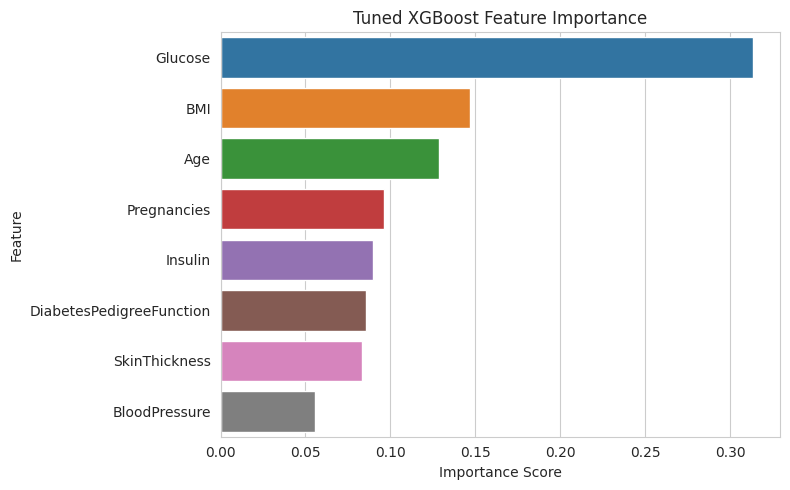

In [33]:
tuned_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(tuned_importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=tuned_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False
)
plt.title('Tuned XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### 3.12 Save the trained model

The tuned model, imputer, and feature list are saved so that the same preprocessing and feature order can be reused later for predictions.


In [34]:
model_package = {
    'model': best_xgb_model,
    'imputer': imputer,
    'features': feature_cols,
    'invalid_zero_columns': cols_with_invalid_zero
}

joblib.dump(model_package, 'xgboost_diabetes_model.pkl')
print("Saved: xgboost_diabetes_model.pkl")

# Optional automatic download in Google Colab
from google.colab import files
files.download('xgboost_diabetes_model.pkl')


Saved: xgboost_diabetes_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Step 4: Final Summary

This notebook completes an end-to-end diabetes classification pipeline:

1. Loaded and inspected the Healthcare Diabetes dataset.
2. Removed duplicate patient records to prevent data leakage.
3. Replaced clinically invalid zero values with missing values and applied median imputation.
4. Performed exploratory analysis, feature engineering, outlier investigation, scaling analysis and PCA.
5. Kept clinically meaningful outliers in the final modelling dataset.
6. Used a stratified 80/20 train-test split.
7. Trained a baseline **XGBoost** classifier.
8. Evaluated it with Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrix and ROC curve.
9. Used stratified 5-fold cross-validation for a more reliable estimate.
10. Tuned XGBoost hyperparameters using GridSearchCV.
11. Evaluated the tuned model on the unseen test set and visualised feature importance.
12. Saved the final trained model for future predictions.

> **Important:** Run all notebook cells from top to bottom to generate the final numerical results for your dataset. Do not report cached or manually typed metric values.
